# Video offset sweep on all good-frame EODs, both directions (3-fish recording)

Results of `offset_sweep_runner.py`: for every good-frame EOD (`good_frames_better_list.csv`), my model of the emitting fish only
(fish 0; BEM σ, sink at the tail tip, the other fish as bodies) rebuilt from the masks and midlines of video frame `Frame + offset`,
offsets −10 … +10 frames (−200 … +200 ms at 50 fps; negative = earlier video frame), and its L2 distance d to the same recorded EOD
(patterns × −1, max |v| = 1). The predicted pattern at every offset is saved with d. Offset 0 is checked against the cached model.
The predicted EODs at the best fixed offset (and at each EOD's own best offset) are saved to
`offset_sweep_all_good_best_offset_predictions.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
RES = 'results/eod_ground_truth_3fish/conductivities'; OUT = f'{RES}/debug_frames'; FPS = 50.0
T = pd.read_csv(f'{RES}/offset_sweep_all_good.csv').sort_values('eod_row').reset_index(drop=True)
OFFSETS = sorted(int(k[2:]) for k in T.columns if k.startswith('d_') and k[2:].lstrip('-').isdigit())
PAIRS = [int(k[3:]) for k in T.columns if k.startswith('r_p')]
D = T[[f'd_{o}' for o in OFFSETS]].to_numpy(); k0 = OFFSETS.index(0); ms = lambda o: f'{1000 * o / FPS:+.0f} ms'
print(f"{len(T)} good-frame EODs, offsets {OFFSETS[0]} … {OFFSETS[-1]} frames; missing (no midline / outside the video): {np.isnan(D).sum()} of {D.size}")
print(f"offset 0 vs the cached model: max |difference| = {np.nanmax(np.abs(T.d_0 - T.d_cached)):.1e}")
U = {o: T[[f'u_{o}_p{q}' for q in PAIRS]].to_numpy() for o in OFFSETS}; R = T[[f'r_p{q}' for q in PAIRS]].to_numpy()

6751 good-frame EODs, offsets -10 … 10 frames; missing (no midline / outside the video): 10 of 141771
offset 0 vs the cached model: max |difference| = 6.4e-12


## d by offset

In [2]:
rng = np.random.default_rng(0); B = 1000
CH = D - D[:, [k0]]
rows = []
for k, o in enumerate(OFFSETS):
    ok = ~np.isnan(CH[:, k]); ch = CH[ok, k]
    boot = [np.median(ch[rng.integers(0, len(ch), len(ch))]) for _ in range(B)] if o else [0, 0]
    rows.append(dict(offset=o, ms=1000 * o / FPS, median_d=np.nanmedian(D[:, k]), mean_d=np.nanmean(D[:, k]),
                     median_change=np.median(ch), ci_lo=np.percentile(boot, 2.5), ci_hi=np.percentile(boot, 97.5),
                     pct_lower=100 * np.mean(ch < 0) if o else np.nan, pct_higher=100 * np.mean(ch > 0) if o else np.nan))
S = pd.DataFrame(rows); print(S.round(3).to_string(index=False))
kb = int(np.lexsort((-S.pct_lower.fillna(-1), S.median_change.where(S.offset != 0, np.inf)))[0]); OB = OFFSETS[kb]   # most negative paired median change
print(f"\nbest fixed offset (most negative median change in d vs offset 0, paired per EOD): {OB} frames ({ms(OB)}): median d {S.median_d[k0]:.3f} -> {S.median_d[kb]:.3f}, "
      f"mean {S.mean_d[k0]:.3f} -> {S.mean_d[kb]:.3f}, lower than at 0 in {S.pct_lower[kb]:.0f} % of EODs "
      f"(median change {S.median_change[kb]:+.3f}, 95 % CI {S.ci_lo[kb]:+.3f} … {S.ci_hi[kb]:+.3f})")
own = np.nanargmin(D, axis=1); T['best_own'] = np.array(OFFSETS)[own]
print(f"each EOD's own best offset: median {T.best_own.median():+.0f} frames; " + ', '.join(f'{o}: {(T.best_own == o).sum()}' for o in OFFSETS))
jump = (D[:, 1:-1] - np.minimum(D[:, :-2], D[:, 2:])) > 1.0       # single-frame spikes (e.g. head-tail flips of a midline)
print(f"single-frame spikes in d (> 1 above both neighbours): {jump.sum()} of {jump.size} values ({100 * jump.mean():.1f} %)")

 offset     ms  median_d  mean_d  median_change  ci_lo  ci_hi  pct_lower  pct_higher
    -10 -200.0     0.655   0.760          0.047  0.037  0.059     43.791      56.209
     -9 -180.0     0.603   0.704          0.021  0.013  0.031     47.258      52.742
     -8 -160.0     0.546   0.644         -0.011 -0.017 -0.002     51.415      48.585
     -7 -140.0     0.483   0.577         -0.046 -0.055 -0.037     56.400      43.600
     -6 -120.0     0.422   0.511         -0.088 -0.100 -0.076     62.889      37.111
     -5 -100.0     0.376   0.459         -0.132 -0.142 -0.119     69.338      30.662
     -4  -80.0     0.364   0.444         -0.145 -0.156 -0.136     74.122      25.878
     -3  -60.0     0.391   0.477         -0.127 -0.137 -0.120     76.744      23.256
     -2  -40.0     0.441   0.535         -0.094 -0.099 -0.087     76.522      23.478
     -1  -20.0     0.499   0.601         -0.047 -0.050 -0.045     74.937      25.063
      0    0.0     0.560   0.666          0.000  0.000  0.000    

## Movement, drift over the recording, per pair

In [3]:
hx = lambda o: T[f'head_x_{o}'].to_numpy(); hy = lambda o: T[f'head_y_{o}'].to_numpy()
T['moved_cm'] = np.hypot(hx(0) - hx(OB), hy(0) - hy(OB)) / (912 / 60)
for lab, m_ in ((f'fish 0 head moved > 1 cm between 0 and {OB} frames', T.moved_cm > 1), ('moved <= 1 cm', T.moved_cm <= 1)):
    print(f"{lab}: {m_.sum()} EODs, median d {np.nanmedian(D[m_, k0]):.3f} -> {np.nanmedian(D[m_, kb]):.3f}, lower in {100 * np.nanmean(CH[m_, kb] < 0):.0f} %, "
          f"own best offset median {T.best_own[m_].median():+.0f}")
q = pd.qcut(T.frame, 4, labels=['1st', '2nd', '3rd', '4th'])
print('\nby quarter of the recording (frames):')
for lab, g in T.groupby(q, observed=True):
    Dg = D[g.index]; print(f"  {lab} quarter (frames {g.frame.min()}–{g.frame.max()}, {len(g)} EODs): best fixed offset {OFFSETS[int(np.nanargmin(np.nanmedian(Dg, axis=0)))]:+d}, "
                           f"own best median {g.best_own.median():+.0f}, median d {np.nanmedian(Dg[:, k0]):.3f} at 0")
res0, resb = np.abs(U[0] - R), np.abs(U[OB] - R)
print(f"\nper pair, median |model - recorded| at 0 -> {OB} frames:")
print('  ' + ', '.join(f'p{p_}: {np.nanmedian(res0[:, j]):.3f} -> {np.nanmedian(resb[:, j]):.3f}' for j, p_ in enumerate(PAIRS)))

fish 0 head moved > 1 cm between 0 and -4 frames: 1762 EODs, median d 0.704 -> 0.345, lower in 86 %, own best offset median -4
moved <= 1 cm: 4989 EODs, median d 0.519 -> 0.370, lower in 70 %, own best offset median -3

by quarter of the recording (frames):
  1st quarter (frames 12–10741, 1688 EODs): best fixed offset -5, own best median -4, median d 0.536 at 0
  2nd quarter (frames 10742–14591, 1688 EODs): best fixed offset -4, own best median -2, median d 0.651 at 0
  3rd quarter (frames 14593–20174, 1687 EODs): best fixed offset -4, own best median -3, median d 0.558 at 0
  4th quarter (frames 20187–34094, 1688 EODs): best fixed offset -4, own best median -3, median d 0.498 at 0

per pair, median |model - recorded| at 0 -> -4 frames:
  p1: 0.084 -> 0.051, p2: 0.098 -> 0.092, p3: 0.057 -> 0.049, p4: 0.060 -> 0.052, p5: 0.080 -> 0.063, p6: 0.079 -> 0.050, p7: 0.098 -> 0.077, p8: 0.150 -> 0.101, p9: 0.129 -> 0.058, p10: 0.156 -> 0.089


## Predicted EODs at the best offset (saved)

In [4]:
P_ = pd.DataFrame(dict(eod_row=T.eod_row, frame=T.frame, best_fixed_offset=OB, own_best_offset=T.best_own,
                       d_0=T.d_0, d_best_fixed=D[:, kb], d_own_best=D[np.arange(len(T)), own]))
for j, p_ in enumerate(PAIRS):
    P_[f'r_p{p_}'] = R[:, j]; P_[f'u0_p{p_}'] = U[0][:, j]; P_[f'ubest_p{p_}'] = U[OB][:, j]
    P_[f'uown_p{p_}'] = np.array([U[OFFSETS[own[n]]][n, j] for n in range(len(T))])
P_.to_csv(f'{RES}/offset_sweep_all_good_best_offset_predictions.csv', index=False)
print(f"saved {len(P_)} EODs: recorded r, model u at offset 0, at the best fixed offset ({OB}) and at each EOD's own best offset "
      f"-> {RES}/offset_sweep_all_good_best_offset_predictions.csv")

saved 6751 EODs: recorded r, model u at offset 0, at the best fixed offset (-4) and at each EOD's own best offset -> results/eod_ground_truth_3fish/conductivities/offset_sweep_all_good_best_offset_predictions.csv


## Figures

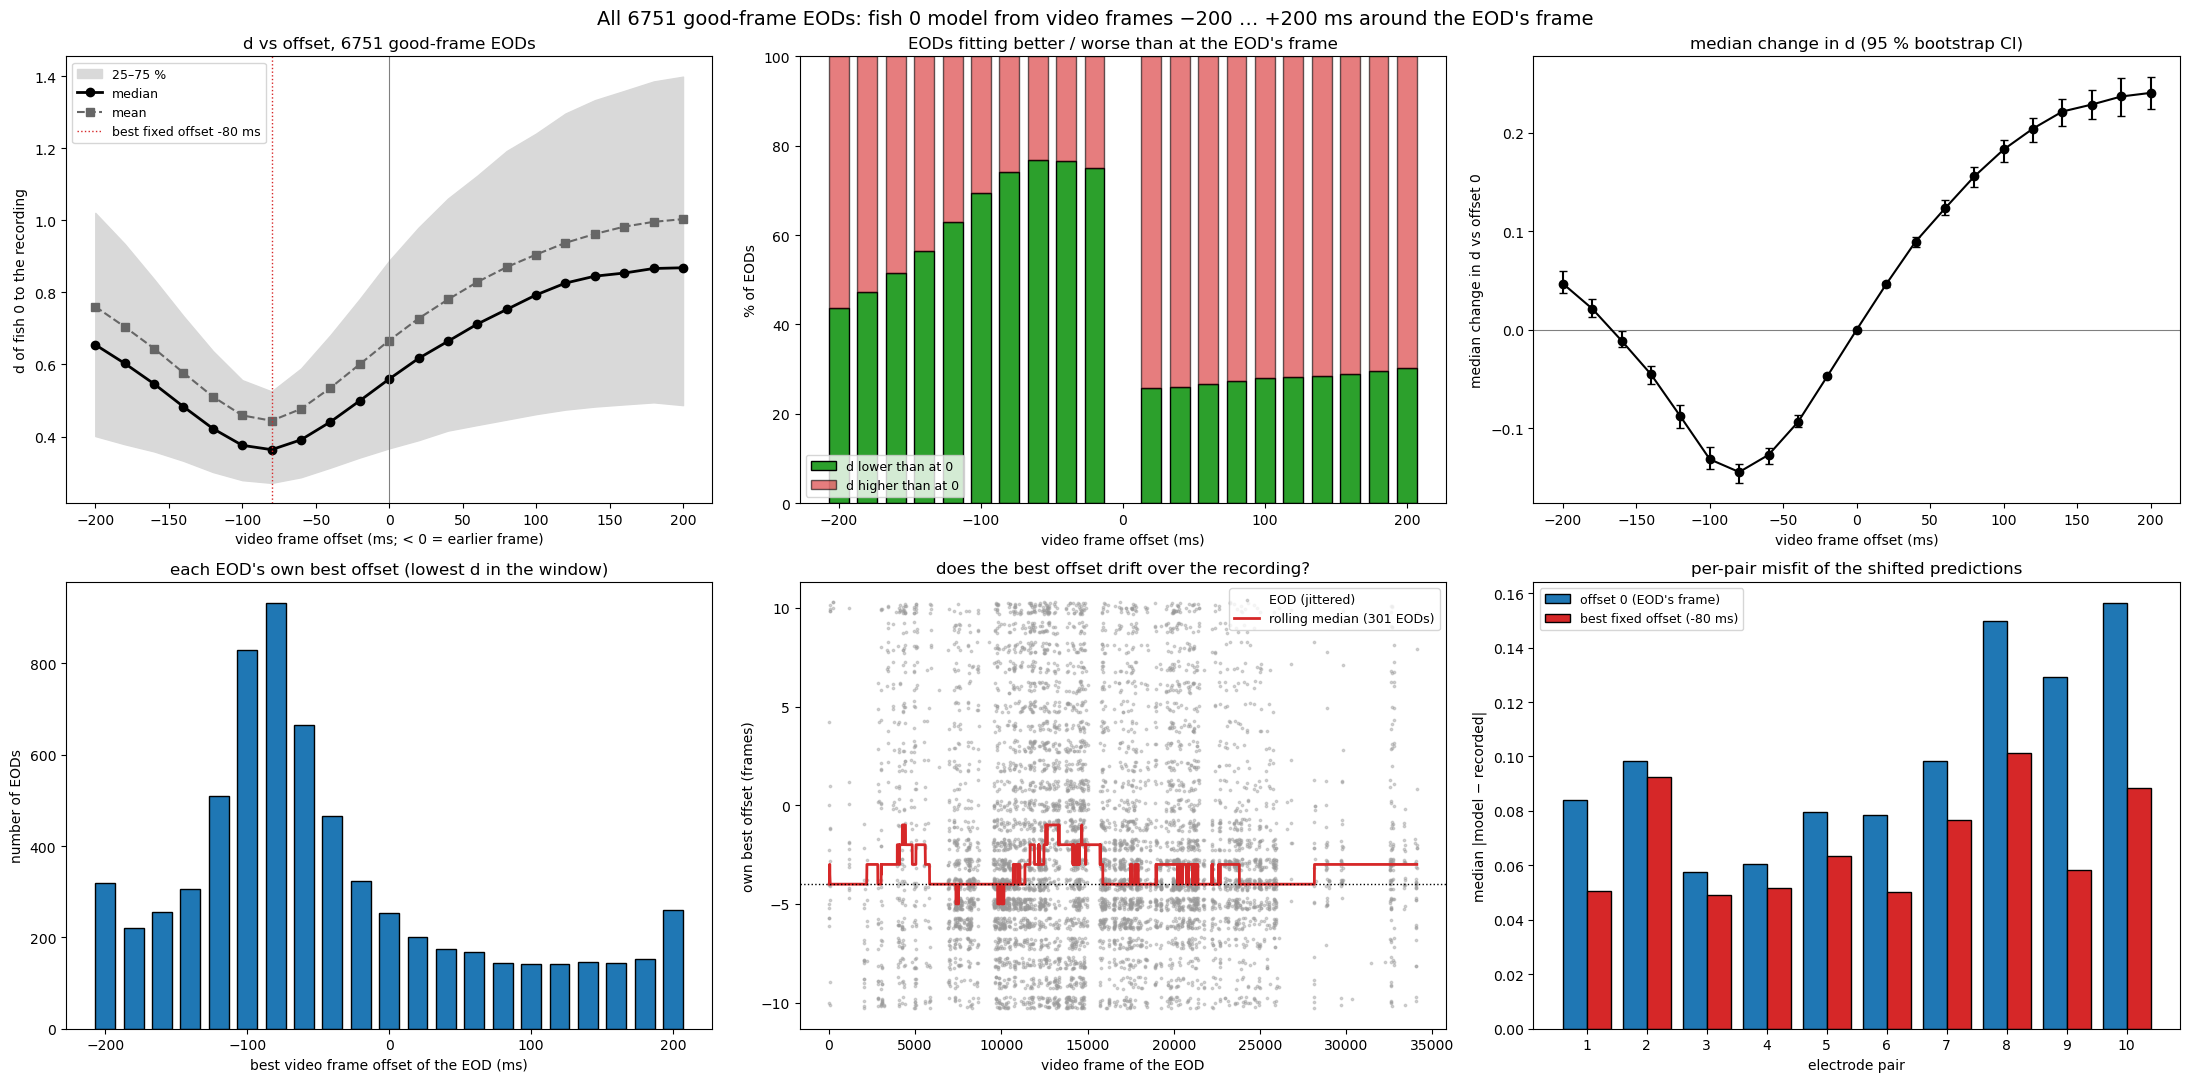

In [5]:
xs = np.array([1000 * o / FPS for o in OFFSETS])
fig, axs = plt.subplots(2, 3, figsize=(22, 11))
a = axs[0, 0]
a.fill_between(xs, np.nanpercentile(D, 25, axis=0), np.nanpercentile(D, 75, axis=0), color='0.85', label='25–75 %')
a.plot(xs, S.median_d, 'o-', color='k', lw=2, label='median'); a.plot(xs, S.mean_d, 's--', color='0.4', label='mean')
a.axvline(0, color='0.5', lw=0.8); a.axvline(1000 * OB / FPS, color='tab:red', lw=1, ls=':', label=f'best fixed offset {ms(OB)}')
a.set(xlabel='video frame offset (ms; < 0 = earlier frame)', ylabel='d of fish 0 to the recording', title=f'd vs offset, {len(T)} good-frame EODs'); a.legend(fontsize=9)
a = axs[0, 1]
a.bar(xs, S.pct_lower, width=14, color='tab:green', edgecolor='k', label='d lower than at 0')
a.bar(xs, S.pct_higher, width=14, bottom=S.pct_lower, color='tab:red', alpha=0.6, edgecolor='k', label='d higher than at 0')
a.set(xlabel='video frame offset (ms)', ylabel='% of EODs', ylim=(0, 100), title='EODs fitting better / worse than at the EOD\'s frame'); a.legend(fontsize=9, loc='lower left')
a = axs[0, 2]
a.errorbar(xs, S.median_change, yerr=[S.median_change - S.ci_lo, S.ci_hi - S.median_change], fmt='o-', color='k', capsize=3)
a.axhline(0, color='0.5', lw=0.8); a.set(xlabel='video frame offset (ms)', ylabel='median change in d vs offset 0', title='median change in d (95 % bootstrap CI)')
a = axs[1, 0]
a.bar(xs, [(T.best_own == o).sum() for o in OFFSETS], width=14, color='tab:blue', edgecolor='k')
a.set(xlabel='best video frame offset of the EOD (ms)', ylabel='number of EODs', title='each EOD\'s own best offset (lowest d in the window)')
a = axs[1, 1]
fr = T.frame.to_numpy(); roll = pd.Series(T.best_own.to_numpy()).rolling(301, center=True, min_periods=50).median()
a.scatter(fr, T.best_own + np.random.default_rng(1).uniform(-0.3, 0.3, len(T)), s=3, color='0.6', alpha=0.4, label='EOD (jittered)')
a.plot(fr, roll, color='tab:red', lw=2, label='rolling median (301 EODs)'); a.axhline(OB, color='k', ls=':', lw=1)
a.set(xlabel='video frame of the EOD', ylabel='own best offset (frames)', title='does the best offset drift over the recording?'); a.legend(fontsize=9)
a = axs[1, 2]; x = np.arange(len(PAIRS))
a.bar(x - 0.2, np.nanmedian(res0, axis=0), 0.4, color='tab:blue', edgecolor='k', label="offset 0 (EOD's frame)")
a.bar(x + 0.2, np.nanmedian(resb, axis=0), 0.4, color='tab:red', edgecolor='k', label=f'best fixed offset ({ms(OB)})')
a.set(xticks=x, xticklabels=PAIRS, xlabel='electrode pair', ylabel='median |model − recorded|', title='per-pair misfit of the shifted predictions'); a.legend(fontsize=9)
fig.suptitle(f'All {len(T)} good-frame EODs: fish 0 model from video frames −200 … +200 ms around the EOD\'s frame', fontsize=14)
plt.tight_layout(); fig.savefig(f'{OUT}/offset_sweep_all_good.png', dpi=100, bbox_inches='tight'); plt.show()